# Series de tiempo 2 — Descomposición de tendencia, estacionalidad y residuo
**Versión comentada y ampliada del cuaderno original.**

## Objetivos
- Reconocer los componentes de una serie temporal.
- Distinguir descomposición **aditiva** y **multiplicativa**.
- Interpretar tendencia, patrón estacional y residuo.
- Evaluar los efectos de ceros, datos faltantes y propagación de cotizaciones.
- Aplicar el análisis a COVID-19 en Colombia, Bitcoin y Nutresa, como en el cuaderno original.

**Alcance:** la descomposición aquí es principalmente **descriptiva**. No es todavía un modelo de pronóstico. El siguiente cuaderno presenta suavización exponencial.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True

## 1. Fundamentos de la descomposición

**Modelo aditivo**

$$X_t=T_t+S_t+R_t$$

La estacionalidad se mide en las mismas unidades de la serie y su amplitud tiende a ser relativamente estable.

**Modelo multiplicativo**

$$X_t=T_t S_t R_t$$

Los efectos estacionales son proporcionales al nivel. Para utilizar la descomposición multiplicativa clásica necesitamos observaciones estrictamente positivas.

En ambos casos, la **tendencia** representa movimientos de largo plazo, la **estacionalidad** fluctuaciones recurrentes de período conocido y el **residuo** la variación no explicada por esos componentes. Un residuo de descomposición no es necesariamente ruido blanco.

La descomposición clásica emplea promedios móviles y un patrón estacional promedio; no debe confundirse con el ajuste de un modelo Holt-Winters o SARIMA.

## 2. Datos históricos de COVID-19 en Colombia
Conservamos la fuente de Johns Hopkins del cuaderno original y la transformación de casos acumulados a casos nuevos reportados.

$$N_t=C_t-C_{t-1}$$

La diferencia inicial se descarta en vez de reemplazarse por cero. Los datos pueden incluir revisiones y retrasos de notificación. La estacionalidad semanal observada puede reflejar el **proceso de reporte**.

In [2]:
url_covid = ("https://raw.githubusercontent.com/CSSEGISandData/COVID-19/"
 "master/csse_covid_19_data/csse_covid_19_time_series/"
 "time_series_covid19_confirmed_global.csv")
covid_raw = pd.read_csv(url_covid)
columnas_fechas = covid_raw.columns[4:]
covid_paises = covid_raw.groupby("Country/Region")[columnas_fechas].sum().T
covid_paises.index = pd.to_datetime(covid_paises.index, format="%m/%d/%y")
covid_paises = covid_paises.sort_index()
display(covid_paises.iloc[:5, :5])

Country/Region,Afghanistan,Albania,Algeria,Andorra,Angola
2020-01-22,0,0,0,0,0
2020-01-23,0,0,0,0,0
2020-01-24,0,0,0,0,0
2020-01-25,0,0,0,0,0
2020-01-26,0,0,0,0,0


Negativos por correcciones: 0
Faltantes: 0


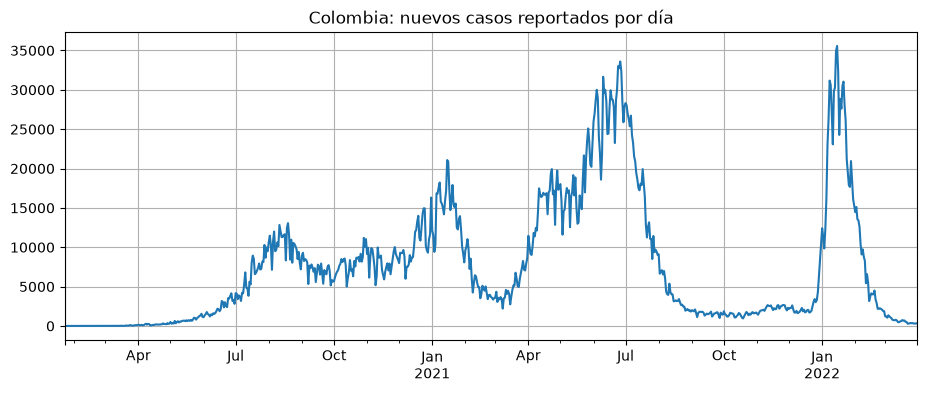

In [3]:
covid_colombia = covid_paises["Colombia"].loc[:"2022-03-31"].diff().dropna()
covid_colombia = covid_colombia.rename("Casos nuevos reportados")
print("Negativos por correcciones:",int((covid_colombia<0).sum()))
print("Faltantes:",int(covid_colombia.isna().sum()))
covid_colombia.plot(title="Colombia: nuevos casos reportados por día")
plt.show()

## 3. Descomposición aditiva
Como los datos son diarios, investigaremos una estacionalidad semanal de **período 7**. Esta elección tiene una interpretación concreta: siete días calendario.

La descomposición requiere una serie regular, al menos dos ciclos completos y valores finitos. Los datos de Johns Hopkins ya vienen en una grilla diaria. `extrapolate_trend="freq"` extiende la estimación de tendencia a los bordes para reducir los `NaN` de la descomposición.

statsmodels: 0.14.6


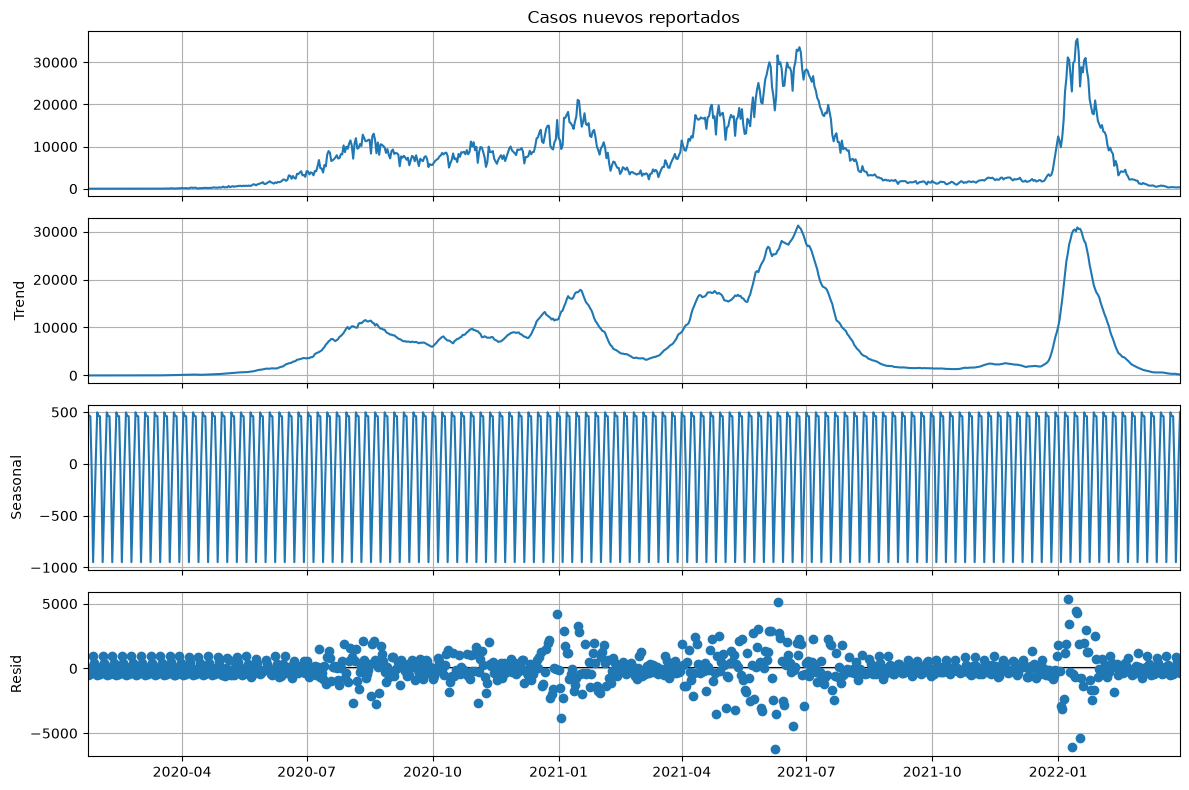

In [4]:
import statsmodels
from statsmodels.tsa.seasonal import seasonal_decompose
print("statsmodels:",statsmodels.__version__)
descomp_aditiva = seasonal_decompose(
    covid_colombia, model="additive", period=7,
    extrapolate_trend="freq"
)
fig = descomp_aditiva.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()

## 4. Inspección del residuo
Un residuo de descomposición puede conservar tendencia local, cambios de varianza o autocorrelación. La media y la varianza móviles ayudan a observar su comportamiento, pero **no prueban por sí solas estacionariedad**.

La varianza móvil utiliza una ventana de 14 días, como en el cuaderno original. Separamos la visualización en cuatro paneles para facilitar la lectura.

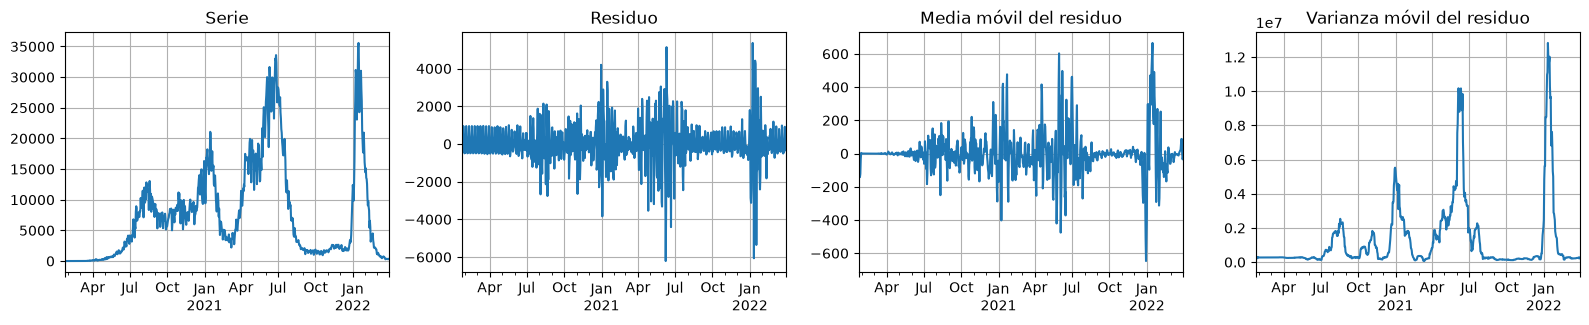

In [5]:
residuo = descomp_aditiva.resid
fig, axes = plt.subplots(1,4,figsize=(16,3.5))
covid_colombia.plot(ax=axes[0],title="Serie")
residuo.plot(ax=axes[1],title="Residuo")
residuo.rolling(14,center=True,min_periods=7).mean().plot(
    ax=axes[2],title="Media móvil del residuo")
residuo.rolling(14,center=True,min_periods=7).var().plot(
    ax=axes[3],title="Varianza móvil del residuo")
plt.tight_layout()
plt.show()

## 5. ¿Cuándo conviene una descomposición multiplicativa?

onstruiremos primero una serie sintética estrictamente positiva cuyo efecto estacional crece con el nivel. Esto permite comprender el significado del modelo multiplicativo sin alterar arbitrariamente los datos históricos.

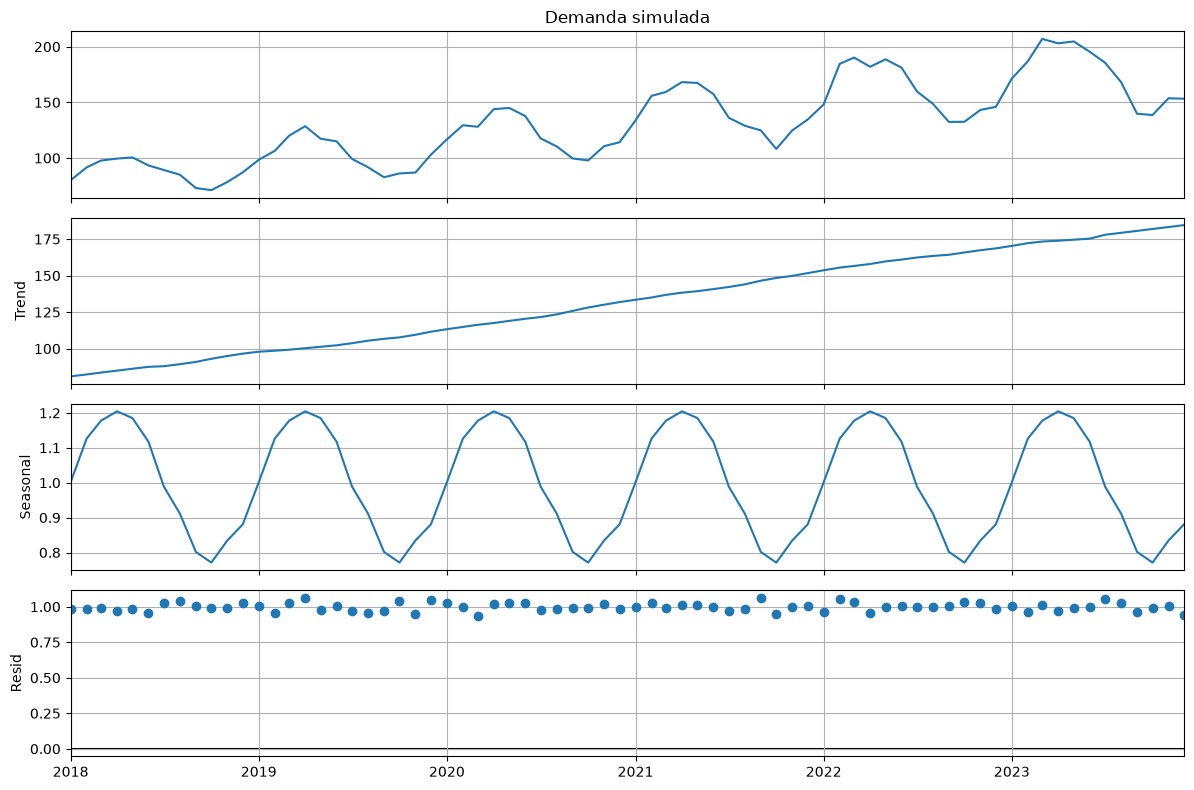

In [6]:
rng = np.random.default_rng(7)
fechas = pd.date_range("2018-01-01",periods=72,freq="MS")
t = np.arange(72)
nivel = 80 + 1.5*t
factor = 1 + 0.22*np.sin(2*np.pi*t/12)
ejemplo_mul = pd.Series(
    nivel*factor*np.exp(rng.normal(0,0.04,len(t))),
    index=fechas,name="Demanda simulada"
)
descomp_mul = seasonal_decompose(
    ejemplo_mul,model="multiplicative",period=12,
    extrapolate_trend="freq"
)
fig = descomp_mul.plot()
fig.set_size_inches(12,8)
plt.tight_layout()
plt.show()

## 6. Interpretación de la componente estacional
En una descomposición aditiva, la estacionalidad está centrada alrededor de cero. En una multiplicativa, los factores estacionales suelen estar centrados alrededor de uno.

Un factor de 1.15 representa aproximadamente un **15 % por encima** de la tendencia; un factor de 0.90 representa aproximadamente un **10 % por debajo**.

El gráfico del cuaderno original aislaba un mes de la estacionalidad de COVID-19. Reproducimos esa idea con la versión aditiva, sin modificar los datos originales.

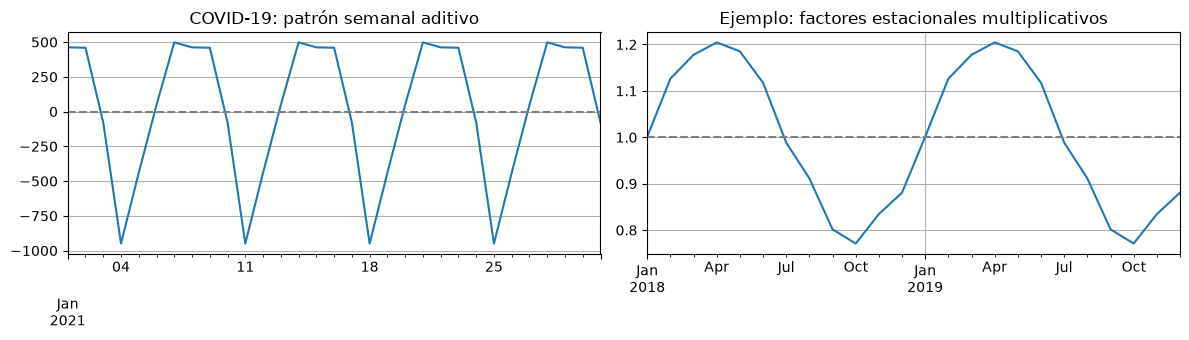

In [7]:
fig, axes = plt.subplots(1,2,figsize=(12,3.5))
descomp_aditiva.seasonal.loc["2021-01-01":"2021-01-31"].plot(
    ax=axes[0],title="COVID-19: patrón semanal aditivo")
descomp_mul.seasonal.iloc[:24].plot(
    ax=axes[1],title="Ejemplo: factores estacionales multiplicativos")
axes[0].axhline(0,color="gray",linestyle="--")
axes[1].axhline(1,color="gray",linestyle="--")
plt.tight_layout()
plt.show()

## 7. Bitcoin: descomposición multiplicativa
Conservamos el ejemplo `BTC-USD` del cuaderno original. Bitcoin suele tener cotizaciones diarias, por lo que una grilla diaria es una representación natural.

**Precaución:** `seasonal_decompose` necesita un período. Elegir `period=7` sirve para investigar una posible variación semanal, **no demuestra** que exista una estacionalidad semanal económicamente significativa.

In [8]:
import yfinance as yf
def obtener_cierre(simbolo, inicio, fin):
    s = yf.Ticker(simbolo).history(start=inicio, end=fin)["Close"].copy()
    if s.empty:
        print(f"Sin cotizaciones: {simbolo}")
        return pd.Series(dtype=float, name=simbolo)
    s.index = pd.to_datetime(s.index).tz_localize(None).normalize()
    s = s.sort_index()
    s.name = simbolo
    return s

Faltantes: 0


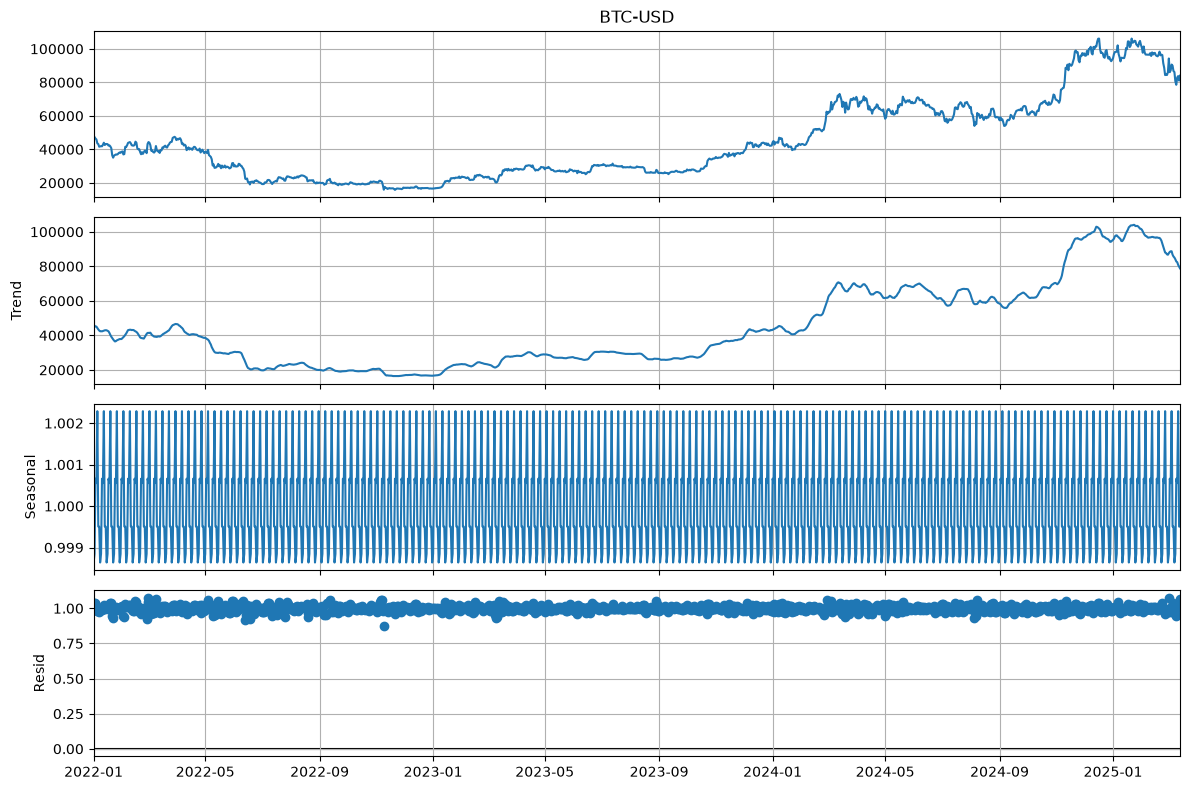

In [9]:
btc = obtener_cierre("BTC-USD","2022-01-01","2025-03-15")
if len(btc)>14:
    btc_diario = btc.asfreq("D")
    print("Faltantes:",btc_diario.isna().sum())
    if btc_diario.notna().all() and (btc_diario>0).all():
        d_btc = seasonal_decompose(
            btc_diario,model="multiplicative",period=7,
            extrapolate_trend="freq")
        fig=d_btc.plot()
        fig.set_size_inches(12,8)
        plt.tight_layout()
        plt.show()
    else:
        print("No se descompone: revisar faltantes o precios no positivos.")
else:
    print("No hay datos suficientes.")

## 8. Nutresa: efecto de `ffill` sobre la descomposición
El cuaderno original utiliza el símbolo `NUTRESA.CL`, descarga precios y completa días calendario con `ffill`.

Aquí conservamos el caso y mostramos la diferencia entre:
- **Sesiones observadas:** solo fechas con precio.
- **Calendario diario con `ffill`:** se repite el último precio en días sin cotización.

Una descomposición con `period=7` sobre la serie rellenada describe parcialmente **la regla de imputación**, no solo el comportamiento del mercado. Por ello, el resultado se presenta como demostración del efecto del preprocesamiento.

Días imputados: 198


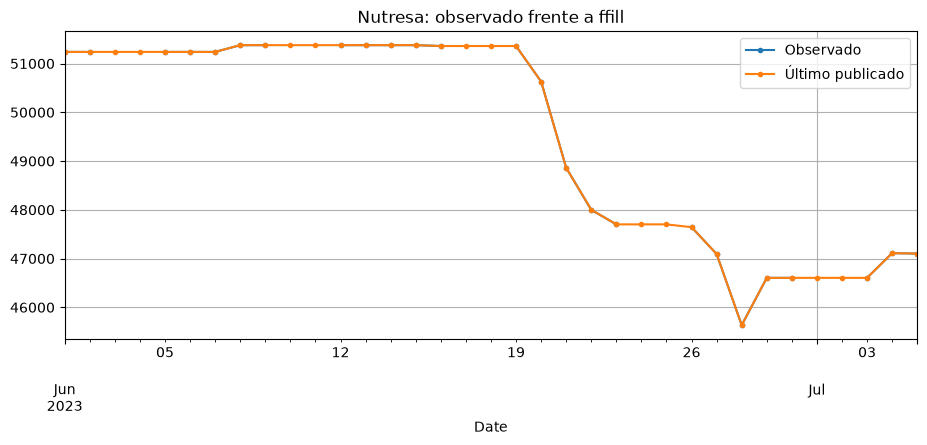

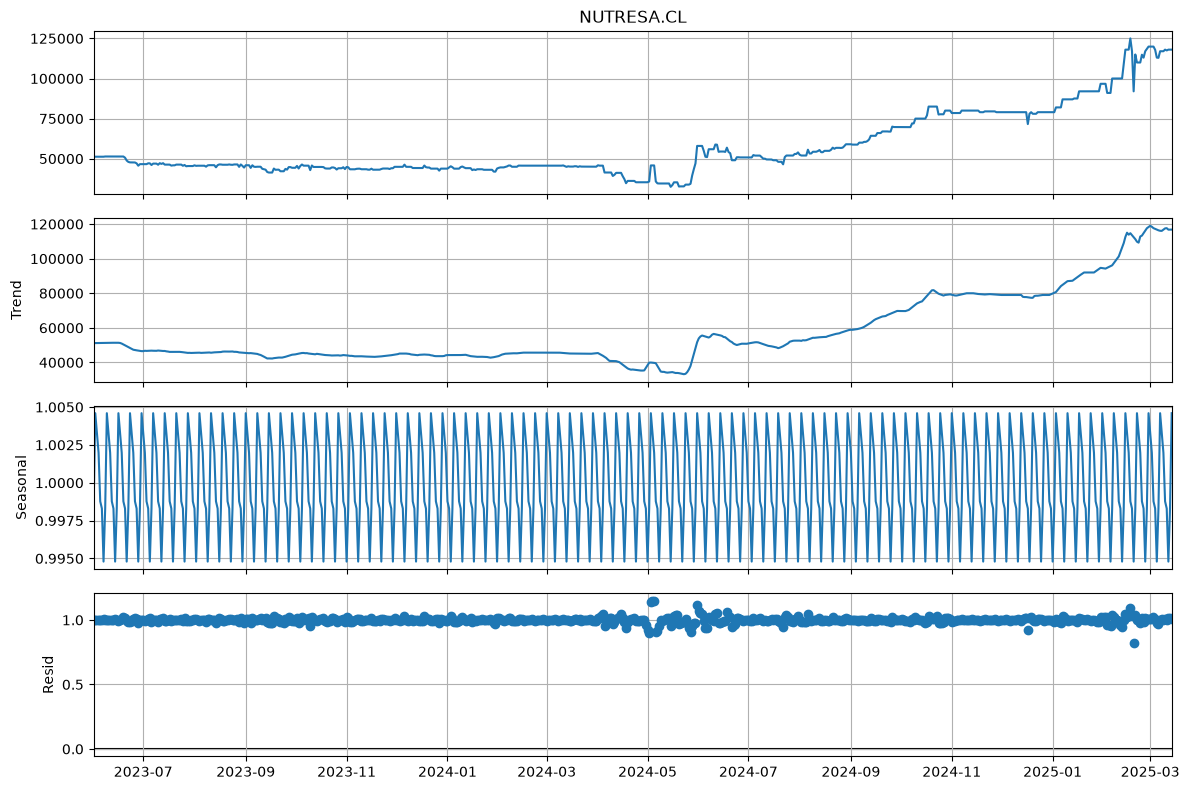

In [10]:
nutresa = obtener_cierre("NUTRESA.CL","2023-06-01","2025-03-15")
if len(nutresa)>14:
    nutresa_diaria = nutresa.asfreq("D")
    nutresa_ffill = nutresa_diaria.ffill()
    print("Días imputados:",int(nutresa_diaria.isna().sum()))
    pd.DataFrame({
        "Observado":nutresa_diaria,
        "Último publicado":nutresa_ffill
    }).iloc[:35].plot(marker=".",title="Nutresa: observado frente a ffill")
    plt.show()
    if (nutresa_ffill>0).all():
        d_nutresa = seasonal_decompose(
            nutresa_ffill,model="multiplicative",period=7,
            extrapolate_trend="freq")
        fig=d_nutresa.plot()
        fig.set_size_inches(12,8)
        plt.tight_layout()
        plt.show()
else:
    print("Ticker sin suficientes observaciones; verificar disponibilidad histórica.")

## 9. Descomposición clásica y STL
La descomposición clásica supone un patrón estacional aproximadamente estable. STL (*Seasonal and Trend decomposition using Loess*) permite estimar tendencia y estacionalidad con mayor flexibilidad y robustez opcional ante valores atípicos.

STL también necesita una escala temporal regular y un período definido. Es una herramienta descriptiva, no un procedimiento de pronóstico por sí solo.

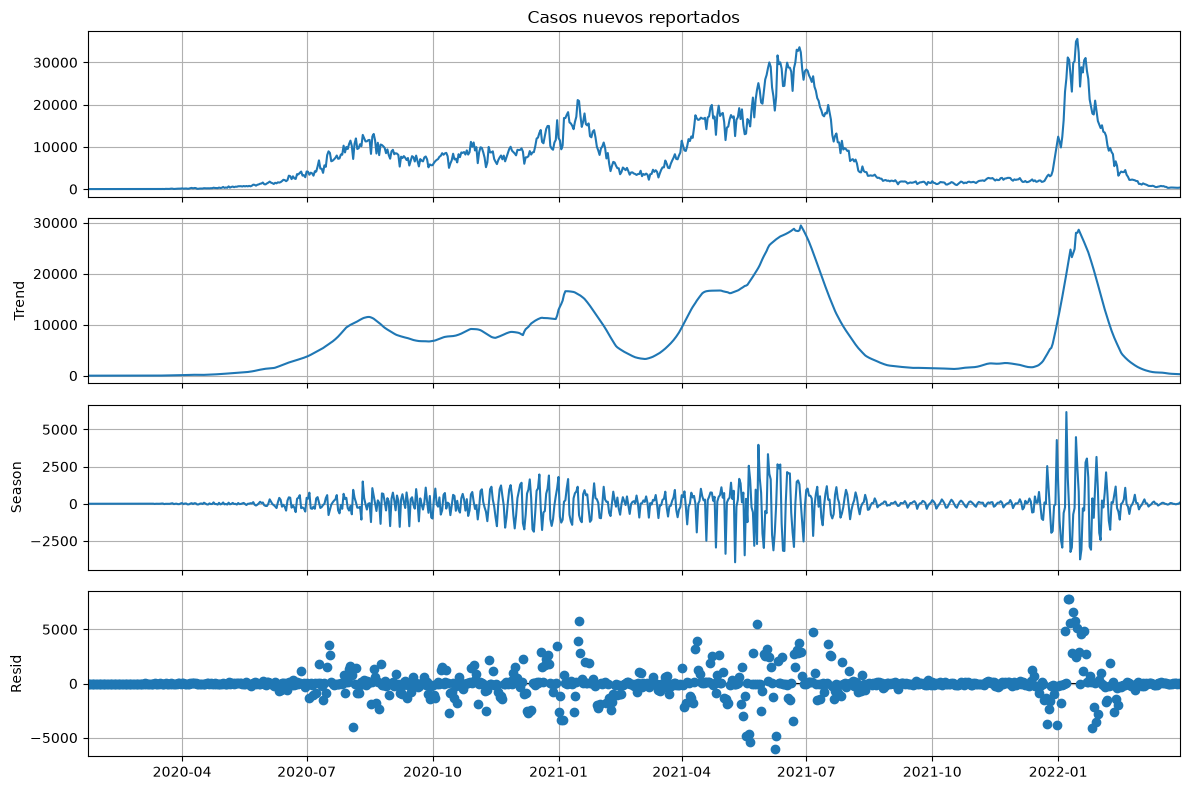

In [11]:
from statsmodels.tsa.seasonal import STL
stl = STL(covid_colombia,period=7,robust=True).fit()
fig=stl.plot()
fig.set_size_inches(12,8)
plt.tight_layout()
plt.show()

## 10. ¿Cómo elegir entre aditiva y multiplicativa?
No existe una regla universal basada solamente en el aspecto visual de los residuos.

- **Aditiva:** fluctuaciones estacionales de amplitud aproximadamente constante.
- **Multiplicativa:** fluctuaciones relativas al nivel, con observaciones positivas.
- **Transformación logarítmica:** para valores positivos, convierte una relación multiplicativa en una estructura aditiva en escala logarítmica, aunque no elimina todos los problemas de modelado.

La elección requiere interpretar la variable, inspeccionar el patrón y evitar transformaciones arbitrarias. Una descomposición descriptiva no demuestra que sus componentes sean procesos causales independientes.